In [1]:
import pandas as pd 
import numpy as np

In [2]:
# importing the data needed
df = pd.read_csv('C:/Users/user/Downloads/listings.csv.gz')

In [3]:
# see how the data looks like
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,8779,https://www.airbnb.com/rooms/8779,20260914164153,2026-09-16,NaN,Kiloranhouse Cottage Master/Jaccuzi,This master Queen double bedroom ( SLEEPS TWO)...,NaN,https://a0.muscache.com/pictures/259325/3b3d7c...,26997,...,4.94,4.63,4.69,NaN,NaN,6,0,5,0,0.11
1,45096,https://www.airbnb.com/rooms/45096,20260914164153,2026-09-16,NaN,Kiloranhouse Cottage Twin Bedroom,This cozy 2 single beds bedroom ( SLEEPS TWO)...,NaN,https://a0.muscache.com/pictures/259420/a81fe1...,26997,...,4.70,4.80,4.70,NaN,NaN,6,0,5,0,0.06
2,45103,https://www.airbnb.com/rooms/45103,20260914164153,2026-09-16,NaN,Kiloranhouse Cottage Loft Bedroom,With view above greenery this single loft bedr...,NaN,https://a0.muscache.com/pictures/259385/48a962...,26997,...,4.69,4.77,4.46,NaN,NaN,6,0,5,0,0.08
3,75683,https://www.airbnb.com/rooms/75683,20260914164153,2026-09-16,NaN,Kiloranhouse Apt Prime Bedroom,This King bed double bedroom ( SLEEPS TWO) wit...,NaN,https://a0.muscache.com/pictures/5497476/24a9d...,26997,...,4.96,4.84,4.72,NaN,NaN,6,0,5,0,0.15
4,75711,https://www.airbnb.com/rooms/75711,20260914164153,2026-09-16,NaN,Kiloranhouse Apt Twin Bedroom - TDB,This triple bedroom SLEEPS TWO (USD 88/night) ...,NaN,https://a0.muscache.com/pictures/5840684/04dd8...,26997,...,5.00,4.78,4.50,NaN,NaN,6,0,5,0,0.11


In [5]:
# find out how any rows iam working with 
df.shape

(22669, 90)

In [8]:
print(df.shape)
df.info()   # or df.columns.tolist() if the output is too long

cols = ['price','neighbourhood_cleansed','room_type','accommodates',
        'bedrooms','availability_365','number_of_reviews',
        'review_scores_rating','reviews_per_month']
df[cols].describe(include='all').T

df[cols].isna().mean().sort_values(ascending=False)

(22669, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22669 entries, 0 to 22668
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            22669 non-null  int64  
 1   listing_url                                   22669 non-null  object 
 2   scrape_id                                     22669 non-null  int64  
 3   last_scraped                                  22669 non-null  object 
 4   source                                        157 non-null    object 
 5   name                                          22669 non-null  object 
 6   description                                   22213 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   22668 non-null  object 
 9   host_id                                       226

review_scores_rating      0.583175
reviews_per_month         0.583175
price                     0.017028
bedrooms                  0.001103
neighbourhood_cleansed    0.000000
room_type                 0.000000
accommodates              0.000000
availability_365          0.000000
number_of_reviews         0.000000
dtype: float64

In [7]:
df.describe(include='object')

,listing_url,last_scraped,source,name,description,picture_url,host_url,host_profile_url,host_name,host_location,...,bathrooms_text,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_raw,has_availability,calendar_last_scraped,first_review,last_review
count,22669,22669,157,22669,22213,22668,22669,22669,22669,12156,...,22542,22669,22283,22559,22559,22559,22412,22669,9449,9449
unique,22669,1,1,21776,16609,22061,12189,12189,4552,440,...,61,18367,3131,189,200,8019,1,1,2568,1840
top,https://www.airbnb.com/rooms/8779,2026-09-16,previous scrape,Home away from home,"Kick back and relax in this calm, stylish space.",https://a0.muscache.com/pictures/miso/Hosting-...,https://www.airbnb.com/users/show/463368190,https://www.airbnb.com/users/profile/147008800...,Howard,"Nairobi, Kenya",...,1 bath,"[""Wifi"", ""Kitchen"", ""TV"", ""Free parking on pre...","$2,590.00",2026-09-16,2026-09-17,"{""quote"": {""taxes"": null, ""currency"": null, ""d...",t,2026-09-16,2026-08-02,2026-08-30
freq,1,22669,157,42,576,17,219,219,291,9995,...,11464,232,624,16433,14579,276,22412,22669,25,161


In [9]:
pd.set_option('display.max_rows', None)
df.iloc[:, 19:88].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22669 entries, 0 to 22668
Data columns (total 69 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   host_location                                 12156 non-null  object 
 1   host_about                                    8570 non-null   object 
 2   host_response_time                            0 non-null      float64
 3   host_response_rate                            0 non-null      float64
 4   host_acceptance_rate                          0 non-null      float64
 5   host_is_superhost                             22669 non-null  object 
 6   host_thumbnail_url                            0 non-null      float64
 7   host_picture_url                              22669 non-null  object 
 8   host_neighbourhood                            0 non-null      float64
 9   host_listings_count                           22669 non-null 

In [10]:
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null': df.notna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(1)
})

pd.set_option('display.max_rows', None)
print(summary)

                                                dtype  non_null  pct_missing
id                                              int64     22669          0.0
listing_url                                    object     22669          0.0
scrape_id                                       int64     22669          0.0
last_scraped                                   object     22669          0.0
source                                         object       157         99.3
name                                           object     22669          0.0
description                                    object     22213          2.0
neighborhood_overview                         float64         0        100.0
picture_url                                    object     22668          0.0
host_id                                         int64     22669          0.0
host_url                                       object     22669          0.0
host_profile_id                                 int64     22669          0.0

In [11]:
# Make a list of the column names we want to check
needed = ['price', 'room_type', 'accommodates', 'bedrooms', 'beds',
          'availability_365', 'number_of_reviews', 'review_scores_rating']

# summary.index holds the column names of your data (one per row of summary)
# .isin(needed) answers True or False: "is this name in my list?"
# summary[...] keeps only the rows where the answer is True
print(summary[summary.index.isin(needed)])

                        dtype  non_null  pct_missing
room_type              object     22669          0.0
accommodates            int64     22669          0.0
bedrooms              float64     22644          0.1
beds                  float64     22287          1.7
price                  object     22283          1.7
availability_365        int64     22669          0.0
number_of_reviews       int64     22669          0.0
review_scores_rating  float64      9449         58.3


In [12]:
# Show the first 10 values of the price column
# We want to see the format: is there a $ sign? commas? what currency?
print(df['price'].head(10))

# Show how many listings have each kind of "missing" price
# isna() marks empty cells as True, sum() counts them
print(df['price'].isna().sum())

0     $7,640.00
1     $6,150.50
2     $4,778.00
3     $7,640.00
4     $6,177.00
5     $6,086.00
6     $8,935.00
7    $19,423.00
8     $2,978.50
9     $5,827.00
Name: price, dtype: object
386


In [13]:
# Turn each price into text, then remove every character that is NOT
# a digit or a decimal point. This strips out "$" and ",".
# r'[^\d.]' means: anything that is not (^) a digit (\d) or a dot (.)
cleaned = df['price'].astype(str).str.replace(r'[^\d.]', '', regex=True)

# Convert the cleaned text into real numbers.
# errors='coerce' turns anything that can't be converted into a blank (NaN)
# instead of crashing the code.
df['price'] = pd.to_numeric(cleaned, errors='coerce')

# Check it worked: count, mean, min, max, median (50%) and more
print(df['price'].describe())

count    2.228300e+04
mean     8.971375e+03
std      4.333931e+04
min      8.789000e+02
25%      3.625000e+03
50%      5.827000e+03
75%      9.064000e+03
max      4.174252e+06
Name: price, dtype: float64


In [14]:
print(df['price'].head(10))

0     7640.0
1     6150.5
2     4778.0
3     7640.0
4     6177.0
5     6086.0
6     8935.0
7    19423.0
8     2978.5
9     5827.0
Name: price, dtype: float64


In [15]:
# Turn off scientific notation so numbers print normally (e.g. 4174252.00)
# {:,.0f} means: show with commas, and 0 decimal places
pd.set_option('display.float_format', '{:,.0f}'.format)

# Show the 15 most expensive prices
# sort_values(ascending=False) sorts from highest to lowest
# head(15) keeps the first 15 rows
print(df['price'].sort_values(ascending=False).head(15))

# quantile() finds the price below which a given share of listings fall.
# 0.95 = the 95th percentile, 0.99 = the 99th, 0.999 = the 99.9th
print(df['price'].quantile([0.50, 0.95, 0.99, 0.999]))

15088   4,174,252
1583    2,978,983
9579    1,257,476
20521   1,219,044
20522   1,219,044
5289    1,178,334
12010   1,035,898
4670    1,035,898
9992      841,667
10111     834,674
9694      731,473
5375      647,436
14828     621,538
13651     585,178
17814     517,949
Name: price, dtype: float64
0     5,827
1    19,682
1    41,329
1   362,564
Name: price, dtype: float64


In [16]:
# Show numbers with commas and 2 decimal places from now on
pd.set_option('display.float_format', '{:,.2f}'.format)

In [17]:
# Count how many listings are above each possible cut-off price
# (df['price'] > 100000) gives True/False for each listing; sum() counts the Trues
for cutoff in [50000, 100000, 200000, 500000]:
    print(cutoff, (df['price'] > cutoff).sum())

# Look at the details of the 15 most expensive listings
# nlargest(15, 'price') picks the 15 rows with the highest price
# The list in [[...]] chooses which columns to show
cols = ['name', 'neighbourhood_cleansed', 'room_type', 'accommodates',
        'bedrooms', 'price', 'availability_365', 'number_of_reviews', 'host_id']
print(df.nlargest(15, 'price')[cols])

50000 180
100000 80
200000 39
500000 16
                                                   name  \
15088          Stylish Riverside retreat near Westlands   
1583                              West suites apartment   
9579                                             Suites   
20521                      The house is good ventilated   
20522  It is seaplane to be and you will find it lovely   
5289       Cavina massoinet Menlik Rd near Yaya centre.   
4670           Beautiful private apartments in Kilimani   
12010                                     null and Void   
9992                          welcome to gold park home   
10111                             a home away from home   
9694          Central and modern 1 bedroom in Westlands   
5375           Lovely fully furnished one bedroom house   
14828                           Self serviced 1 bedroom   
13651      Chic 1 bedroom apartment in serene Westlands   
672                                         wills house   

      neighbour

In [18]:
# Make the printed output wider so columns stay on one line
pd.set_option('display.width', 250)

In [19]:
# Keep only the listings priced above 50,000 KES, in a new table called "high"
high = df[df['price'] > 50000]

# How many of these 180 have at least one review?
# (high['number_of_reviews'] > 0) gives True/False for each row; sum() counts the Trues
print((high['number_of_reviews'] > 0).sum())

# Summary of reviews and availability for this group
# describe() gives count, mean, min, median (50%) and max
print(high[['number_of_reviews', 'availability_365']].describe())

# Which hosts appear most often in this group?
# value_counts() counts how many times each host_id appears; head(5) shows the top 5
print(high['host_id'].value_counts().head(5))

32
       number_of_reviews  availability_365
count             180.00            180.00
mean                3.52            341.90
std                13.04             52.25
min                 0.00             11.00
25%                 0.00            360.00
50%                 0.00            365.00
75%                 0.00            365.00
max               126.00            365.00
host_id
188921258    16
534124797     8
35945714      8
715647152     4
407626104     3
Name: count, dtype: int64


In [20]:
# Make sure printed tables stay on one line
pd.set_option('display.width', 250)

# Split the 180 expensive listings into price bands
# pd.cut() sorts each price into a band defined by the "bins" edges
bands = pd.cut(high['price'],
               bins=[50000, 100000, 200000, 500000, float('inf')])

# Add a True/False column: has this listing ever been reviewed?
reviewed = high['number_of_reviews'] > 0

# For each band, count the listings and count how many were reviewed
# groupby(bands) makes one group per band
# agg(['count', 'sum']) gives the number of rows and the number of Trues
print(reviewed.groupby(bands, observed=True).agg(['count', 'sum']))

# Show the reviewed listings only, highest price first
# sort_values('price', ascending=False) puts the most expensive on top
cols = ['price', 'number_of_reviews', 'availability_365',
        'room_type', 'bedrooms', 'neighbourhood_cleansed']
print(high[reviewed][cols].sort_values('price', ascending=False).head(15))

                      count  sum
price                           
(50000.0, 100000.0]     100   21
(100000.0, 200000.0]     41    7
(200000.0, 500000.0]     23    1
(500000.0, inf]          16    3
             price  number_of_reviews  availability_365        room_type  bedrooms neighbourhood_cleansed
15088 4,174,252.00                  9               365  Entire home/apt      1.00               Kilimani
1583  2,978,983.00                  1               365  Entire home/apt      0.00                Langata
9694    731,473.00                  3               360  Entire home/apt      1.00               Kilimani
134     207,050.00                 38               269     Private room      1.00               Kilimani
51      185,814.00                 52               147  Entire home/apt      3.00              Westlands
1043    153,961.00                  7               365  Entire home/apt      3.00              Westlands
369     130,782.00                 25               270  Ent

In [21]:
# Create a new column that is True when the price is above 100,000 KES
# and False otherwise. Listings with no price get False for now.
df['price_outlier'] = df['price'] > 100000

# Count how many listings are flagged (should be 80)
# value_counts() counts how many True and how many False
print(df['price_outlier'].value_counts())

# Build a cleaned table for our analysis, leaving df itself untouched.
# ~df['price_outlier']  means "NOT an outlier" (~ flips True and False)
# df['price'].notna()   means "has a price"
# & means "and": we keep rows that satisfy BOTH conditions
# .copy() makes a separate table, so changes to it don't affect df
df_clean = df[(~df['price_outlier']) & (df['price'].notna())].copy()

# Check how many listings remain, and re-run the price summary
print(len(df_clean))
print(df_clean['price'].describe())

price_outlier
False    22589
True        80
Name: count, dtype: int64
22203
count   22,203.00
mean     7,545.72
std      7,040.11
min        878.90
25%      3,595.82
50%      5,827.00
75%      8,935.00
max     99,058.00
Name: price, dtype: float64


In [22]:
# How many listings have each number of bedrooms?
# value_counts() counts them; sort_index() orders by bedroom number, not by count
print(df_clean['bedrooms'].value_counts().sort_index())

# Same check for how many guests a listing sleeps
print(df_clean['accommodates'].value_counts().sort_index())

# Find listings where the numbers don't make sense together:
# more than 10 bedrooms, or more bedrooms than guests it accommodates
odd = df_clean[(df_clean['bedrooms'] > 10) |
               (df_clean['bedrooms'] > df_clean['accommodates'])]

# How many are there?
print(len(odd))

# Look at them (| means "or", & would mean "and")
print(odd[['name', 'bedrooms', 'accommodates', 'room_type', 'price']].head(10))

bedrooms
0.00      1437
1.00     12687
2.00      5561
3.00      1758
4.00       423
5.00       175
6.00        42
7.00        13
8.00        17
9.00         6
10.00       17
11.00        3
12.00        3
13.00        1
14.00        2
15.00        5
16.00        3
17.00        2
21.00        1
24.00        3
25.00        1
27.00        5
30.00        2
32.00        1
33.00        1
35.00        2
37.00        1
40.00        1
50.00        6
Name: count, dtype: int64
accommodates
1       673
2     12354
3      1252
4      5201
5       560
6      1384
7       143
8       265
9        44
10      188
11       15
12       39
13        4
14       10
15        8
16       63
Name: count, dtype: int64
165
                                                 name  bedrooms  accommodates        room_type     price
26                                          Hob House      7.00             2       Hotel room 12,949.00
37                  HOTEL SOUTHERN BLUE NAIROBI,KENYA     50.00             2     Pri

In [ ]:
# How many listings sleep each number of guests?
# head(12) shows only the first 12 rows, so the output stays short
print(df_clean['accommodates'].value_counts().sort_index().head(12))

accommodates
1       673
2     12354
3      1252
4      5201
5       560
6      1384
7       143
8       265
9        44
10      188
11       15
12       39
Name: count, dtype: int64


In [ ]:
# How many listings did the "odd" filter catch? 
print(len(odd))

165


In [25]:
# pd.cut() sorts each number into a band defined by the bin edges
# bins=[-1, 0, 1, 2, 3, inf] makes these bands:
#   (-1, 0]  -> 0 bedrooms (studio or single room)
#   (0, 1]   -> 1 bedroom
#   (1, 2]   -> 2 bedrooms
#   (2, 3]   -> 3 bedrooms
#   (3, inf] -> 4 or more
# labels gives each band a readable name, in the same order
df_clean['bedroom_group'] = pd.cut(
    df_clean['bedrooms'],
    bins=[-1, 0, 1, 2, 3, float('inf')],
    labels=['Studio/0', '1', '2', '3', '4+']
)

# How many listings are in each band?
# sort_index() keeps the bands in their natural order, not by size
print(df_clean['bedroom_group'].value_counts().sort_index())

# Split the bands by room type: rows are room types, columns are bands
# crosstab() counts how many listings fall in each combination
print(pd.crosstab(df_clean['room_type'], df_clean['bedroom_group']))

bedroom_group
Studio/0     1437
1           12687
2            5561
3            1758
4+            736
Name: count, dtype: int64
bedroom_group    Studio/0      1     2     3   4+
room_type                                        
Entire home/apt      1135  10353  5154  1627  572
Hotel room              3     44     2     6    3
Private room          290   2275   404   123  161
Shared room             9     15     1     2    0


In [26]:
# Keep only the rows where room_type is exactly "Entire home/apt"
# == means "is equal to" (a single = would assign a value instead)
# .copy() makes a separate table so changes don't touch df_clean
df_homes = df_clean[df_clean['room_type'] == 'Entire home/apt'].copy()

# How many listings are in it?
print(len(df_homes))

18857


In [27]:
# A list of word fragments to look for in column names
keywords = ['estimated', 'review', 'last', 'ltm', 'l30d']

# Go through every column name in df_clean and keep it if it contains
# ANY of the keywords. "for c in ..." means "for each column name c".
# "any(k in c for k in keywords)" means "is at least one keyword inside c?"
matches = [c for c in df_clean.columns if any(k in c for k in keywords)]

# Show the matching column names
print(matches)

['last_scraped', 'calendar_last_scraped', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'reviews_per_month']


In [28]:
# The three demand columns we want to inspect
cols = ['estimated_occupancy_l365d', 'estimated_revenue_l365d',
        'number_of_reviews_ltm']

# How many blanks does each column have in df_homes?
# isna() marks blanks as True, sum() counts them
print(df_homes[cols].isna().sum())

# Count, mean, median (50%), min and max for each column
print(df_homes[cols].describe())

# How many entire homes have zero estimated revenue?
# (== 0 gives True/False per row; sum() counts the Trues)
print((df_homes['estimated_revenue_l365d'] == 0).sum())

# How many had at least one review in the last 12 months?
print((df_homes['number_of_reviews_ltm'] > 0).sum())

# Check the relationship: do occupancy x price and the revenue column match?
# head(5) shows only the first five rows
print(df_homes[['price', 'estimated_occupancy_l365d',
                'estimated_revenue_l365d']].head(5))

estimated_occupancy_l365d    0
estimated_revenue_l365d      0
number_of_reviews_ltm        0
dtype: int64
       estimated_occupancy_l365d  estimated_revenue_l365d  number_of_reviews_ltm
count                  18,857.00                18,857.00              18,857.00
mean                       15.43               113,393.48                   2.61
std                        39.26               364,421.51                   7.10
min                         0.00                     0.00                   0.00
25%                         0.00                     0.00                   0.00
50%                         0.00                     0.00                   0.00
75%                         6.00                51,276.00                   1.00
max                       255.00            10,006,710.00                 100.00
12836
6021
      price  estimated_occupancy_l365d  estimated_revenue_l365d
6  8,935.00                          0                     0.00
8  2,978.50               

In [29]:
# Keep only the entire homes with at least 1 review in the last 12 months
# > 0 means "greater than zero"; .copy() makes a separate table
df_active = df_homes[df_homes['number_of_reviews_ltm'] > 0].copy()

# How many active listings do we have? (should be 6,021)
print(len(df_active))

# How many listings are in each neighbourhood?
# value_counts() counts the rows per neighbourhood name, biggest first
counts = df_active['neighbourhood_cleansed'].value_counts()

# How many different neighbourhoods are there in total?
print(len(counts))

# Show the 15 neighbourhoods with the most active listings
print(counts.head(15))

# How many neighbourhoods have at least 30 active listings?
# (counts >= 30) gives True/False per neighbourhood; sum() counts the Trues
print((counts >= 30).sum())

6021
15
neighbourhood_cleansed
Kilimani            2895
Kibra                708
Westlands            600
Langata              459
Roysambu             330
Starehe              312
Embakasi East        218
Dagoretti            180
Kasarani             172
Embakasi South       104
Embakasi West         16
Makadara              12
Kamukunji              9
Embakasi Central       4
Ruaraka                2
Name: count, dtype: int64
10


In [30]:
# Make a list of the neighbourhoods with at least 30 active listings
# counts[counts >= 30] keeps only those; .index gives their names
big = counts[counts >= 30].index

# Keep only the active listings that are in those 10 neighbourhoods
# isin(big) answers True/False: "is this neighbourhood in my list?"
df_big = df_active[df_active['neighbourhood_cleansed'].isin(big)]

# Group the listings by neighbourhood and calculate one summary row for each
# Format of each line:  new_column_name = ('column to use', 'calculation')
summary = df_big.groupby('neighbourhood_cleansed').agg(
    listings=('id', 'count'),                          # number of listings
    median_price=('price', 'median'),                  # typical nightly price (KES)
    median_nights=('estimated_occupancy_l365d', 'median'),  # typical nights booked
    median_revenue=('estimated_revenue_l365d', 'median'),   # typical yearly revenue
    median_rating=('review_scores_rating', 'median')   # typical guest rating
)

# Show the table, with the highest median revenue at the top
# ascending=False means "largest first"
print(summary.sort_values('median_revenue', ascending=False))

                        listings  median_price  median_nights  median_revenue  median_rating
neighbourhood_cleansed                                                                      
Westlands                    600      8,935.00          24.00      238,000.00           4.91
Kilimani                    2895      7,251.00          24.00      201,996.00           4.90
Langata                      459      5,827.00          24.00      177,180.00           4.88
Kibra                        708      6,345.00          24.00      163,146.00           4.94
Dagoretti                    180      2,719.00          33.00      103,320.00           4.84
Kasarani                     172      3,937.00          18.00       77,697.00           4.92
Starehe                      312      3,367.00          18.00       70,371.00           4.75
Roysambu                     330      2,590.00          18.00       64,926.00           4.86
Embakasi South               104      3,237.00          18.00       60

In [31]:
# Start from ALL entire homes (active and inactive) in the 10 big neighbourhoods
homes_big = df_homes[df_homes['neighbourhood_cleansed'].isin(big)]

# True/False for each listing: was it reviewed in the last 12 months?
active_flag = homes_big['number_of_reviews_ltm'] > 0

# Group by neighbourhood and take the mean of the True/False values.
# The mean of True/False is the fraction of Trues, so * 100 gives a percentage.
share = active_flag.groupby(homes_big['neighbourhood_cleansed']).mean() * 100

# Total number of entire homes in each neighbourhood
total = homes_big['neighbourhood_cleansed'].value_counts()

# Put both side by side and sort by the share that are active
risk = pd.DataFrame({'all_homes': total, 'pct_active': share.round(1)})
print(risk.sort_values('pct_active', ascending=False))

                        all_homes  pct_active
neighbourhood_cleansed                       
Westlands                    1421       42.20
Dagoretti                     499       36.10
Kibra                        2010       35.20
Langata                      1318       34.80
Kilimani                     8599       33.70
Starehe                      1152       27.10
Embakasi South                411       25.30
Kasarani                      690       24.90
Roysambu                     1487       22.20
Embakasi East                1042       20.90


In [32]:
# Keep only the active Kibra listings
kibra = df_active[df_active['neighbourhood_cleansed'] == 'Kibra']

# How many different hosts are there? (nunique counts distinct values)
print(kibra['host_id'].nunique())

# Which hosts have the most listings there?
print(kibra['host_id'].value_counts().head(5))

511
host_id
655425576    10
433121604     9
469114228     8
712945388     8
73356840      7
Name: count, dtype: int64


In [33]:
# Average estimated yearly revenue per entire home, INCLUDING the inactive
# homes (they count as 0). This answers: "if I picked a random entire home
# in this area, what would it earn on average?"
avg_all = (homes_big.groupby('neighbourhood_cleansed')
                    ['estimated_revenue_l365d'].mean().round(0))

# Put the pieces we've built side by side in one table.
# All of these are indexed by neighbourhood name, so pandas lines them up.
result = pd.DataFrame({
    'all_homes': total,                                  # entire homes in the area
    'pct_active': share.round(1),                        # % with a review in last 12 months
    'median_revenue_active': summary['median_revenue'],  # typical active home
    'avg_revenue_all_homes': avg_all                     # average, inactive included
})

# Show it, with the highest average at the top
print(result.sort_values('avg_revenue_all_homes', ascending=False))

                        all_homes  pct_active  median_revenue_active  avg_revenue_all_homes
neighbourhood_cleansed                                                                     
Westlands                    1421       42.20             238,000.00             224,346.00
Langata                      1318       34.80             177,180.00             145,334.00
Kilimani                     8599       33.70             201,996.00             136,956.00
Kibra                        2010       35.20             163,146.00             114,737.00
Dagoretti                     499       36.10             103,320.00              67,007.00
Kasarani                      690       24.90              77,697.00              64,876.00
Starehe                      1152       27.10              70,371.00              40,510.00
Embakasi South                411       25.30              60,600.00              35,346.00
Roysambu                     1487       22.20              64,926.00            

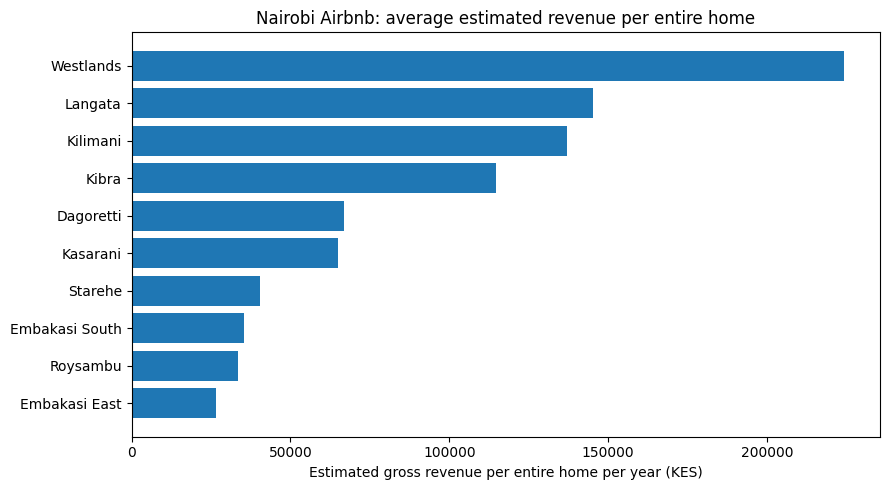

In [34]:
import matplotlib.pyplot as plt

# Take the average revenue column and sort it from smallest to largest.
# Horizontal bar charts draw the first item at the bottom,
# so sorting small-to-large puts the biggest bar at the top.
plot_data = result['avg_revenue_all_homes'].sort_values()

# Create an empty chart canvas, 9 inches wide and 5 inches tall
plt.figure(figsize=(9, 5))

# Draw horizontal bars: names on the vertical axis, values for the bar lengths
plt.barh(plot_data.index, plot_data.values)

# Labels so a reader knows exactly what they are looking at
plt.xlabel('Estimated gross revenue per entire home per year (KES)')
plt.title('Nairobi Airbnb: average estimated revenue per entire home')

# Show full numbers like 200000 instead of 2e5 on the horizontal axis
plt.ticklabel_format(style='plain', axis='x')

# Adjust spacing so nothing is cut off, then display the chart
plt.tight_layout()
plt.show()

# Save the whole results table as a CSV file in your working folder,
# so you can load it into Power BI later.
# The neighbourhood names are the index, so they are saved too.
result.to_csv('neighbourhood_summary.csv')

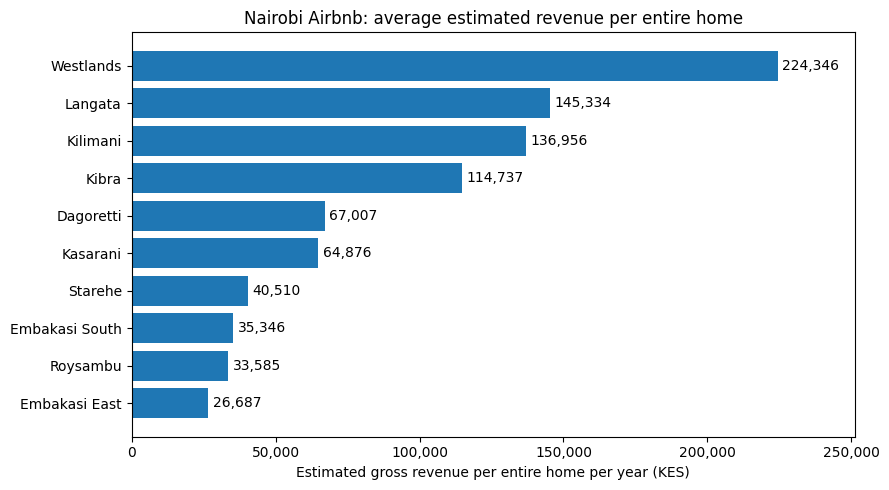

In [36]:
plt.figure(figsize=(9, 5))
bars = plt.barh(plot_data.index, plot_data.values)

# Put the value at the end of each bar.
# plt.bar_label() adds text to bars; fmt controls how the number looks.
# '{:,.0f}' means: commas for thousands, no decimal places.
plt.bar_label(bars, fmt='{:,.0f}', padding=3)

# Show thousands separators on the horizontal axis, e.g. 200,000.
# FuncFormatter lets us apply our own format to every tick label.
from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Leave a bit of room on the right so the longest label isn't cut off
plt.xlim(0, plot_data.max() * 1.12)

plt.xlabel('Estimated gross revenue per entire home per year (KES)')
plt.title('Nairobi Airbnb: average estimated revenue per entire home')
plt.tight_layout()
# Save the chart as a PNG image in your working folder.
# dpi=200 makes it sharp enough for a portfolio or README.
# bbox_inches='tight' trims extra white space around the edges.
plt.savefig('revenue_by_neighbourhood.png', dpi=200, bbox_inches='tight')
plt.show()

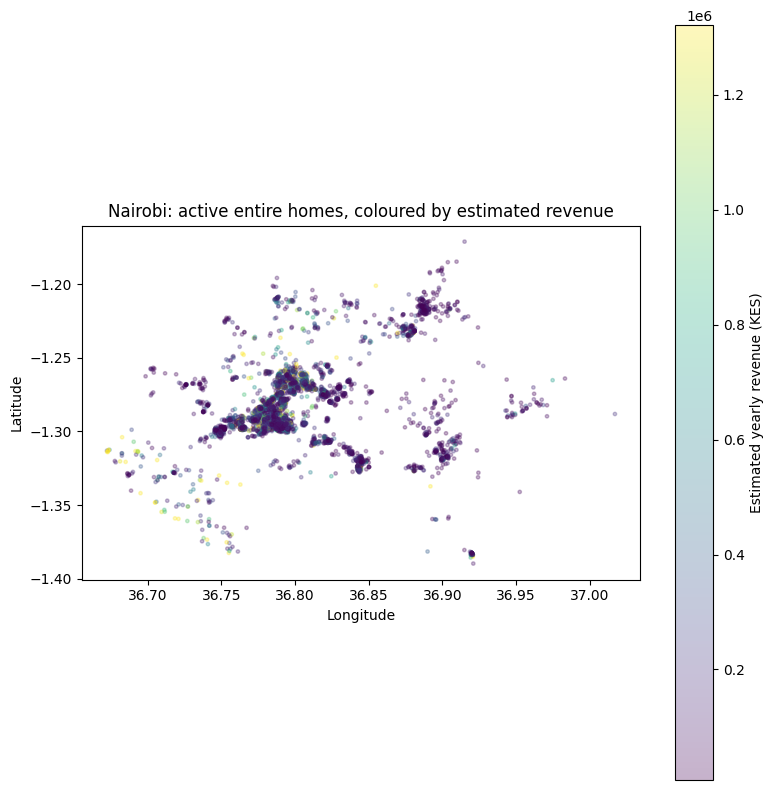

In [37]:
# Make an empty chart canvas, 8 inches wide and 8 inches tall
plt.figure(figsize=(8, 8))

# Plot every active entire home as a dot.
# Longitude is the east-west position, so it goes on the horizontal axis (x).
# Latitude is the north-south position, so it goes on the vertical axis (y).
#   s=6        makes each dot small
#   alpha=0.3  makes dots semi-transparent, so places with many
#              overlapping listings look darker
#   c=...      colours each dot by its estimated yearly revenue
#   vmax=...   caps the colour scale at the 95th percentile, so a few
#              very high earners don't wash out all the other colours
points = plt.scatter(
    df_active['longitude'], df_active['latitude'],
    s=6, alpha=0.3,
    c=df_active['estimated_revenue_l365d'],
    vmax=df_active['estimated_revenue_l365d'].quantile(0.95)
)

# A colour bar acts as the legend, showing what the colours mean
plt.colorbar(points, label='Estimated yearly revenue (KES)')

# Axis labels and a title
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Nairobi: active entire homes, coloured by estimated revenue')

# Make a degree of longitude and a degree of latitude the same length on
# screen, so the map isn't stretched
plt.gca().set_aspect('equal')

# Tidy the spacing, save a copy as an image, then display it.
# savefig must come BEFORE show(), or the saved file can be blank.
plt.tight_layout()
plt.savefig('nairobi_map.png', dpi=200, bbox_inches='tight')
plt.show()

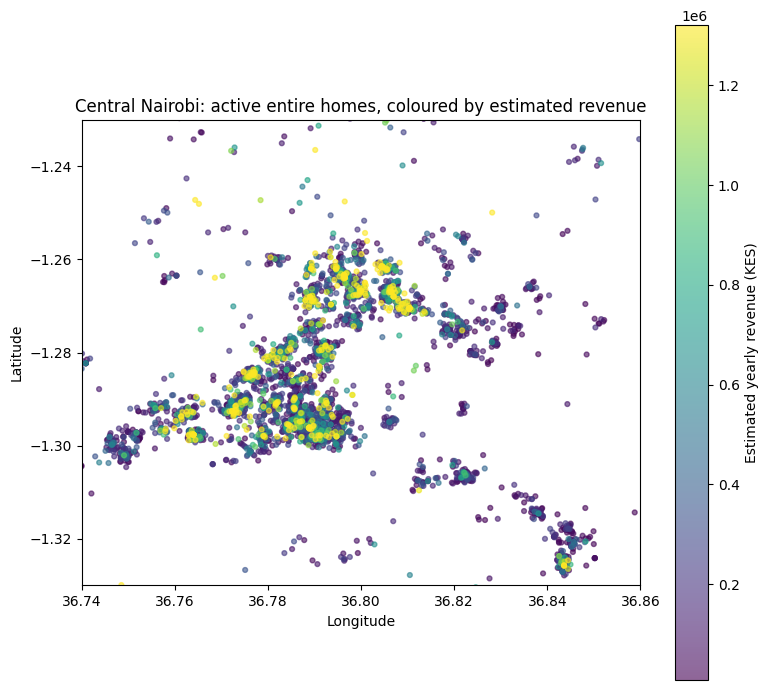

In [38]:
# Sort the listings from lowest to highest revenue.
# Dots are drawn in the order they appear, so the highest earners
# will be drawn last and sit on top instead of being buried.
plot_df = df_active.sort_values('estimated_revenue_l365d')

plt.figure(figsize=(8, 7))

# Same scatter as before, with slightly bigger and less transparent dots
points = plt.scatter(
    plot_df['longitude'], plot_df['latitude'],
    s=12, alpha=0.6,
    c=plot_df['estimated_revenue_l365d'],
    vmax=plot_df['estimated_revenue_l365d'].quantile(0.95)
)
plt.colorbar(points, label='Estimated yearly revenue (KES)')

# Zoom in on the dense central area.
# xlim sets the left and right edges, ylim sets the bottom and top.
plt.xlim(36.74, 36.86)
plt.ylim(-1.33, -1.23)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Central Nairobi: active entire homes, coloured by estimated revenue')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.savefig('nairobi_map_zoomed.png', dpi=200, bbox_inches='tight')
plt.show()

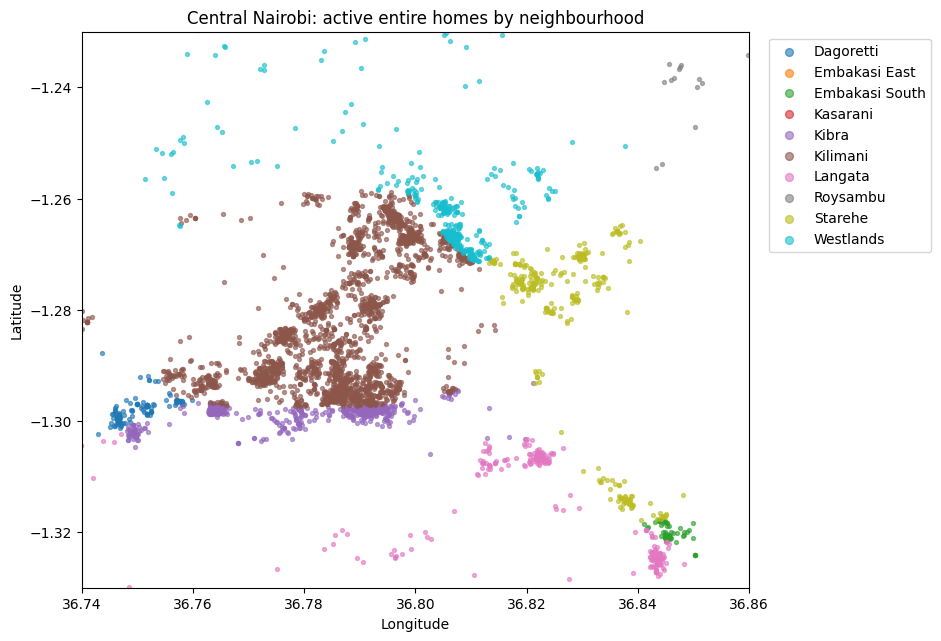

In [39]:
# Keep only the 10 neighbourhoods we compared, so the legend stays readable
plot_big = df_active[df_active['neighbourhood_cleansed'].isin(big)]

plt.figure(figsize=(9, 7))

# Loop over the neighbourhoods one at a time.
# "for name, group in ..." splits the data into one small table per
# neighbourhood: "name" is its name and "group" holds its listings.
for name, group in plot_big.groupby('neighbourhood_cleansed'):
    # Draw this neighbourhood's dots in one colour, labelled with its name
    plt.scatter(group['longitude'], group['latitude'],
                s=8, alpha=0.6, label=name)

# Same zoom as before
plt.xlim(36.74, 36.86)
plt.ylim(-1.33, -1.23)

# Legend outside the plot, so it doesn't cover any dots.
# markerscale=2 makes the legend dots bigger and easier to see.
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), markerscale=2)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Central Nairobi: active entire homes by neighbourhood')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.savefig('nairobi_map_by_area.png', dpi=200, bbox_inches='tight')
plt.show()

In [40]:
# --- File 1: the neighbourhood summary table ---
# "summary" holds the medians we calculated in Step 14.
# "result" holds the active share and average revenue from Step 16.
# We keep only the three columns from "result" that "summary" doesn't have,
# and join the two tables side by side (they share neighbourhood names as the index).
full_summary = summary.join(result[['all_homes', 'pct_active', 'avg_revenue_all_homes']])

# Move the neighbourhood name from the index into a normal column,
# so Power BI sees it as a proper field called "neighbourhood"
full_summary = full_summary.reset_index().rename(
    columns={'neighbourhood_cleansed': 'neighbourhood'})

# Save it as a CSV file. index=False stops pandas adding a 0,1,2... column.
full_summary.to_csv('neighbourhood_summary.csv', index=False)

# --- File 2: one row per active entire home, for the map and detail charts ---
# Choose only the columns we need, which keeps the file small and tidy
keep = ['id', 'neighbourhood_cleansed', 'latitude', 'longitude', 'price',
        'bedrooms', 'bedroom_group', 'accommodates',
        'estimated_occupancy_l365d', 'estimated_revenue_l365d',
        'number_of_reviews_ltm', 'review_scores_rating']

# Save only the listings in the 10 neighbourhoods we compared (df_big, from Step 14)
df_big[keep].to_csv('listings_active.csv', index=False)

# Print where the files were saved and how big each table is
import os
print(os.getcwd())
print(full_summary.shape, df_big[keep].shape)

c:\Users\user\AppData\Local\Programs\Microsoft VS Code
(10, 9) (5978, 12)


In [41]:
# os lets Python work with folders and file paths
import os

# Build a path to a new folder called "nairobi_airbnb" inside your Documents.
# expanduser('~') means "the current user's home folder", so this works
# without typing your username.
folder = os.path.join(os.path.expanduser('~'), 'Documents', 'nairobi_airbnb')

# Create the folder. exist_ok=True means "don't complain if it already exists".
os.makedirs(folder, exist_ok=True)

# Save both files into that folder.
# os.path.join glues the folder and the file name together correctly.
full_summary.to_csv(os.path.join(folder, 'neighbourhood_summary.csv'), index=False)
df_big[keep].to_csv(os.path.join(folder, 'listings_active.csv'), index=False)

# Print the folder so you know exactly where to look
print(folder)

C:\Users\user\Documents\nairobi_airbnb
